# WTI Crude Oil: Return vs. Volatility Predictability

Twenty years of daily WTI futures (2006-2026) with macro (DXY, VIX) and EIA inventory features.

- **Part 1** asks whether an XGBoost model can predict 5-day WTI returns out of sample (2024-2026). It cannot: the rank IC
  is slightly negative and the long-short strategy loses money while buy-and-hold gains.
- **Part 2** reframes the target as 5-day realized volatility, compares HAR, Ridge, Lasso, Random Forest and XGBoost in a
  yearly walk-forward (2016-2026), and uses the forecasts to size a volatility-targeted position.

Leakage controls used throughout: every feature is lagged one day; EIA weekly stocks are joined only from their
release date (week-ending Friday + 5 days); a 5-day purge separates train / validation / test; winsorization bounds,
scalers and imputers are fit on training data only; signal ranks use a trailing 252-day window, never the full sample.

In [1]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
np.random.seed(42)
data_dir = "data"
horizon = 5                  # predict the next 5 trading days
n_group = 5                  # number of quantile groups
cost_bps = 5.0               # one-way transaction cost of 5 bps (slippage + impact)
random_state = 42
release_lag = 5              # EIA weekly stocks: week ends on Friday, released the next Wednesday (+5 days)

In [2]:
import os
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.alpha': 0.25, 'grid.linewidth': 0.6, 'font.size': 10})

## 1. Data
WTI front-month futures, DXY, VIX and futures volume (`data/df.csv`), WTI spot price from FRED (`data/WTI_spot_price.csv`), and EIA weekly U.S. crude stocks excluding SPR (`data/stocks.xlsx`). See `data/README.md`.

In [3]:
df=pd.read_csv(data_dir+"/df.csv")
spot_price=pd.read_csv(data_dir+"/WTI_spot_price.csv")
stocks=pd.read_excel(data_dir+"/stocks.xlsx")

In [4]:
spot_price=spot_price.rename(columns={'observation_date':'Date'})
spot_price['Date']=pd.to_datetime(spot_price['Date']).dt.normalize().astype('datetime64[ns]')
spot_price=spot_price.set_index('Date').sort_index()
spot_price=spot_price[~spot_price.index.duplicated(keep='last')]
spot_price['DCOILWTICO']=pd.to_numeric(spot_price['DCOILWTICO'],errors='coerce')
spot_price=spot_price.ffill()
print(spot_price.index)

DatetimeIndex(['2006-01-03', '2006-01-04', '2006-01-05', '2006-01-06',
               '2006-01-09', '2006-01-10', '2006-01-11', '2006-01-12',
               '2006-01-13', '2006-01-16',
               ...
               '2026-03-31', '2026-04-01', '2026-04-02', '2026-04-03',
               '2026-04-06', '2026-04-07', '2026-04-08', '2026-04-09',
               '2026-04-10', '2026-04-13'],
              dtype='datetime64[ns]', name='Date', length=5290, freq=None)


In [5]:
stocks['Date']=pd.to_datetime(stocks['Date']).dt.normalize().astype('datetime64[ns]')
stocks=stocks.set_index('Date').sort_index()
stocks=stocks[~stocks.index.duplicated(keep='last')]
inv_col=[col for col in stocks.columns if 'Stocks' in col][0]
stocks=stocks.rename(columns={inv_col:'inventory'})
print(stocks.index)

DatetimeIndex(['1982-08-20', '1982-08-27', '1982-09-24', '1982-10-01',
               '1982-10-08', '1982-10-15', '1982-10-22', '1982-10-29',
               '1982-11-05', '1982-11-12',
               ...
               '2026-02-06', '2026-02-13', '2026-02-20', '2026-02-27',
               '2026-03-06', '2026-03-13', '2026-03-20', '2026-03-27',
               '2026-04-03', '2026-04-10'],
              dtype='datetime64[ns]', name='Date', length=2272, freq=None)


Inventory year-over-year change, shifted to the date it becomes public (Friday week-end + 5 days, i.e. the following Wednesday).

In [6]:
inv_lag=stocks['inventory'].astype(float).copy()
inv_lag.index=inv_lag.index+pd.Timedelta(days=364)
stocks['inv_yoy']=stocks['inventory'].astype(float)/inv_lag.reindex(stocks.index)-1
# available date = week-ending Friday + 5 days
inv_avail=stocks[['inv_yoy']].dropna()
inv_avail.index=inv_avail.index+pd.Timedelta(days=release_lag)
inv_avail.index.name='Date'

In [7]:
df['Date']=pd.to_datetime(df['Date']).dt.normalize().astype('datetime64[ns]')
df=df.set_index('Date').sort_index()
df=df[~df.index.duplicated(keep='last')]

In [8]:
df=df.join(spot_price['DCOILWTICO'],how='left')
df['DCOILWTICO']=df['DCOILWTICO'].ffill()
df

,WTI,DXY,VIX,Volume,DCOILWTICO
Date,,,,,
2006-01-03,63.139999,89.839996,11.140000,130635.0,63.11
2006-01-04,63.419998,89.139999,11.370000,105194.0,63.41
2006-01-05,62.790001,89.330002,11.310000,104035.0,62.81
2006-01-06,64.209999,88.849998,11.000000,110763.0,64.21
2006-01-09,63.500000,89.250000,11.130000,115558.0,63.56
...,...,...,...,...,...
2026-04-02,111.540001,100.029999,23.870001,0.0,113.23
2026-04-06,112.410004,99.980003,24.170000,271742.0,114.01
2026-04-07,112.949997,99.639999,25.780001,429331.0,114.58


In [9]:
df = pd.merge_asof(df, inv_avail, left_index=True, right_index=True, direction='backward')
df

,WTI,DXY,VIX,Volume,DCOILWTICO,inv_yoy
Date,,,,,,
2006-01-03,63.139999,89.839996,11.140000,130635.0,63.11,0.100046
2006-01-04,63.419998,89.139999,11.370000,105194.0,63.41,0.109224
2006-01-05,62.790001,89.330002,11.310000,104035.0,62.81,0.109224
2006-01-06,64.209999,88.849998,11.000000,110763.0,64.21,0.109224
2006-01-09,63.500000,89.250000,11.130000,115558.0,63.56,0.109224
...,...,...,...,...,...,...
2026-04-02,111.540001,100.029999,23.870001,0.0,113.23,0.049669
2026-04-06,112.410004,99.980003,24.170000,271742.0,114.01,0.049669
2026-04-07,112.949997,99.639999,25.780001,429331.0,114.58,0.049669


## 2. Data checks
The negative print on 2020-04-20 and zero-volume days are handled before computing returns.

In [10]:
# data checks
print("WTI <= 0:", list(df.index[df['WTI']<=0].strftime('%Y-%m-%d')))
print("Volume == 0:", list(df.index[df['Volume']==0].strftime('%Y-%m-%d')))
df['Volume']=df['Volume'].replace(0,np.nan)

WTI <= 0: ['2020-04-20']
Volume == 0: ['2023-04-06', '2025-06-18', '2025-07-03', '2025-07-04', '2025-08-29', '2025-11-03', '2026-04-02']


## 3. Features
Momentum, moving-average gaps, realized volatility, spot-futures basis, dollar and VIX changes, volume ratio and inventory signal. All features are shifted by one day.

In [11]:
# Feature engineering
def safe_ret(price, n=1):
    p = price.where(price > 0)
    return p / p.shift(n) - 1

def make_features_mid_low(df, horizon=5):
    x = df.copy()
    p = x['WTI'].where(x['WTI'] > 0)
    spot = x['DCOILWTICO'].where(x['DCOILWTICO'] > 0)
    # momentum & moving-average gaps
    for w in [3, 5, 10, 20]:
        x[f'ret_{w}'] = safe_ret(x['WTI'], w)
    for w in [5, 20]:
        ma = p.rolling(w).mean()
        x[f'ma_gap_{w}'] = p / ma - 1
    # volatility
    for w in [10, 20]:
        x[f'vol_{w}'] = safe_ret(x['WTI'], 1).rolling(w).std()
    # term structure (spot vs. futures)
    x['Basis'] = (spot - p) / p
    x['Basis_chg'] = x['Basis'].diff(1)
    # macro
    x['DXY_ret'] = x['DXY'].pct_change(1, fill_method=None)
    x['DXY_ret_5'] = x['DXY'].pct_change(5, fill_method=None)
    x['VIX_chg'] = x['VIX'].pct_change(1, fill_method=None)
    x['Vol_ratio'] = x['Volume'] / x['Volume'].rolling(20, min_periods=10).mean()
    # inventory
    x['inv_signal'] = x['inv_yoy'].ewm(span=5, adjust=False).mean()
    # label: next `horizon`-day return
    x['target'] = safe_ret(x['WTI'], horizon).shift(-horizon)
    # used by the backtest only
    x['ret_1d'] = safe_ret(x['WTI'], 1)
    x['fwd_ret_1'] = x['ret_1d'].shift(-1)
    return x

In [12]:
final_df=make_features_mid_low(df, horizon)

In [13]:
# explicit feature list
feature_cols=['ret_3','ret_5','ret_10','ret_20','ma_gap_5','ma_gap_20','vol_10','vol_20','Basis','Basis_chg',
              'DXY_ret','DXY_ret_5','VIX','VIX_chg','Vol_ratio','inv_yoy','inv_signal']

In [14]:
# lagging
final_df[feature_cols]=final_df[feature_cols].shift(1)
clean_df = final_df.dropna(subset=feature_cols + ['target']).copy()
clean_df

,WTI,DXY,VIX,Volume,DCOILWTICO,inv_yoy,ret_3,ret_5,ret_10,ret_20,...,Basis,Basis_chg,DXY_ret,DXY_ret_5,VIX_chg,Vol_ratio,inv_signal,target,ret_1d,fwd_ret_1
Date,,,,,,,,,,,,,,,,,,,,,
2006-02-02,64.680000,89.370003,12.360000,150155.0,64.71,0.090744,-0.017710,0.010782,0.012627,0.054165,...,7.512386e-04,0.001635,0.006183,0.013359,-0.045560,1.235304,0.087286,-0.031849,-0.028245,0.010668
2006-02-03,65.370003,89.889999,13.230000,110816.0,65.41,0.090744,-0.053694,-0.023845,-0.032171,0.019868,...,4.638172e-04,-0.000287,-0.001564,0.008463,0.070388,1.298910,0.088439,-0.054000,0.010668,-0.003977
2006-02-06,65.110001,90.290001,12.960000,97538.0,65.11,0.090744,-0.037544,-0.035272,-0.043599,0.041089,...,6.118594e-04,0.000148,0.005818,0.006382,-0.020408,0.955806,0.089207,-0.059438,-0.003977,-0.031024
2006-02-07,63.090000,90.239998,13.040000,145683.0,63.01,0.090744,-0.021785,-0.047403,-0.043906,0.014017,...,-9.374160e-09,-0.000612,0.004450,0.009729,0.006173,0.846107,0.089720,-0.055793,-0.031024,-0.008559
2006-02-08,62.549999,90.430000,13.590000,150436.0,62.51,0.090744,-0.024583,-0.071113,-0.059201,-0.006457,...,-1.268032e-03,-0.001268,-0.000554,0.014388,0.042178,1.247448,0.090061,-0.077538,-0.008559,0.001119
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-26,94.480003,99.900002,25.330000,350768.0,96.18,0.052022,-0.081367,-0.062292,0.035186,0.380618,...,1.317538e-02,0.004188,0.001710,-0.004896,-0.060111,0.700141,0.035143,0.180567,0.046058,0.054615
2026-03-27,99.639999,100.150002,27.440001,374920.0,101.26,0.052022,0.072053,-0.017266,-0.013058,0.448858,...,1.799319e-02,0.004818,0.003012,0.006752,0.083300,0.613973,0.040769,0.128161,0.054615,0.032517
2026-03-30,102.879997,100.510002,31.049999,374075.0,104.69,0.052022,0.078939,0.013426,0.009422,0.486720,...,1.625854e-02,-0.001735,0.002503,0.005018,0.131560,0.659836,0.044520,0.097881,0.032517,-0.014580


## 4. Part 1 - Can we predict 5-day returns?
Train 2006-2021, validate 2022-2023 (early stopping on rank IC), test 2024 onward, with a 5-day purge at each boundary.

In [15]:
# Part 1: can we predict 5-day returns?
# date split with purge
train_df=clean_df.loc[:'2021-12-31'].iloc[:-horizon]
valid_df=clean_df.loc['2022-01-01':'2023-12-31'].iloc[:-horizon]
test_df=clean_df.loc['2024-01-01':].copy()
print('Train:', train_df.index[0].date(), '->', train_df.index[-1].date(), len(train_df))
print('Valid:', valid_df.index[0].date(), '->', valid_df.index[-1].date(), len(valid_df))
print('Test :', test_df.index[0].date(), '->', test_df.index[-1].date(), len(test_df))

Train: 2006-02-02 -> 2021-12-23 3862
Valid: 2022-01-03 -> 2023-12-21 495
Test : 2024-01-02 -> 2026-04-01 536


In [16]:
def neg_rank_ic(y_true, y_pred):
    ic = spearmanr(y_true, y_pred).statistic
    return 0.0 if np.isnan(ic) else -float(ic)

def xgbmodel(train_df, valid_df):
    lo, hi = train_df['target'].quantile([0.01, 0.99])
    model=xgb.XGBRegressor(n_estimators=500, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0, random_state=random_state,
    eval_metric=neg_rank_ic, early_stopping_rounds=50, n_jobs=-1)
    model.fit(train_df[feature_cols], train_df['target'].clip(lo, hi),
              eval_set=[(valid_df[feature_cols], valid_df['target'].clip(lo, hi))], verbose=False)
    return model
logic_model=xgbmodel(train_df, valid_df)
print('best_iteration:', logic_model.best_iteration)

best_iteration: 57


In [17]:
def testdf(model, start):
    out = final_df.loc[start:].copy()
    out['pred'] = model.predict(out[feature_cols])
    return out
logic_test_df=testdf(logic_model, valid_df.index[0])

Quantile backtest of the out-of-sample predictions: EMA-smoothed signal, trailing 252-day percentile rank, long the top / short the bottom group, volatility-scaled, with VIX-scaled transaction costs (5 bps one-way base).

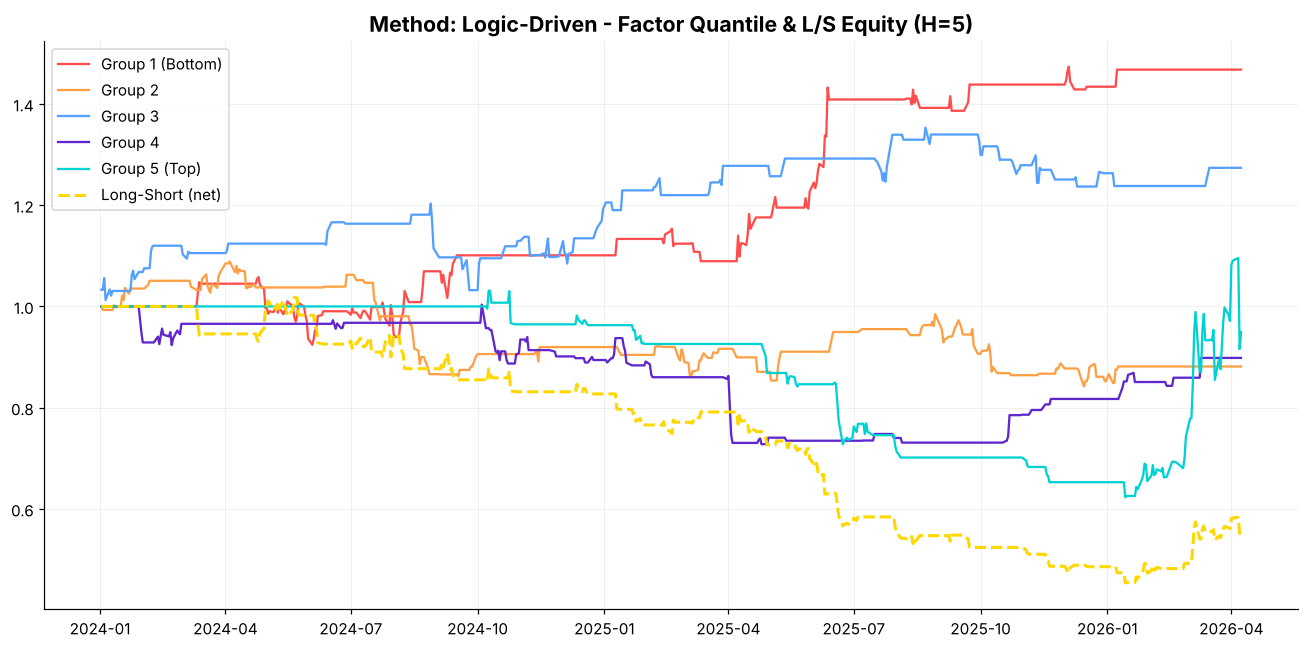

{'Method': 'Logic-Driven', 'Period': '2024-01-02 -> 2026-04-08', 'Cumulative Return': '-44.24%', 'Buy&Hold WTI': '40.52%', 'Rank IC (5d)': '-0.0688', 'Sharpe Ratio': '-1.276', 'Max Drawdown': '-55.43%', 'Win Rate': '45.18%'}


In [18]:
def factor_group_backtest(df, eval_start, n_groups=5, cost_bps=5.0, horizon=5, split_name="Unknown"):
    out = df.copy()
    # 1. smooth the signal with an EMA, then rank it against the past 252 days only (no full-sample ranking)
    out['pred_smooth']=out['pred'].ewm(span=horizon, adjust=False).mean()
    out['pred_rank'] = out['pred_smooth'].rolling(252, min_periods=60).rank(pct=True)
    out['group'] = np.ceil(out['pred_rank'] * n_groups).clip(1, n_groups)
    # 2. long & short, the signal deviates from its recent mean
    out['position'] = 0.0
    pred_mean = out['pred_smooth'].rolling(20).mean()
    pred_std = out['pred_smooth'].rolling(20).std()
    mask_long=(out['group']==n_groups)&(out['pred_smooth']>(pred_mean + 0.2 * pred_std))
    mask_short=(out['group']==1)&(out['pred_smooth']<(pred_mean - 0.2 * pred_std))
    out.loc[mask_long, 'position'] = 1.0
    out.loc[mask_short, 'position'] = -1.0
    # 3. volatility scaling; reference level：rolling 1-year median
    out['realized_vol'] = out['ret_1d'].rolling(20, min_periods=10).std()
    vol_ref = out['realized_vol'].rolling(252, min_periods=60).median()
    vol_scalar = (vol_ref / out['realized_vol']).fillna(1).clip(0.3, 1.2)
    out['position'] = out['position'] * vol_scalar
    out = out.loc[eval_start:]
    out = out[out.index <= df['fwd_ret_1'].last_valid_index()].copy()
    out['daily_ret'] = out['fwd_ret_1']
    out['turnover'] = out['position'].diff().abs()
    out.loc[out.index[0], 'turnover'] = abs(out['position'].iloc[0])
    vol_factor = 1 + (out['VIX'].ffill().fillna(20) / 50)
    out['cost'] = out['turnover'] * cost_bps * 1e-4 * vol_factor
    out['net_ret'] = (out['position'] * out['daily_ret']).fillna(0) - out['cost']
    out['equity'] = (1 + out['net_ret']).cumprod()
    # 4. metrics
    ic_df = out[['pred', 'target']].dropna()
    ic = spearmanr(ic_df['pred'], ic_df['target']).statistic
    ann = 252
    sharpe = out['net_ret'].mean() / (out['net_ret'].std() + 1e-12) * np.sqrt(ann)
    cum_ret = out['equity'].iloc[-1] - 1
    bh_ret = (1 + out['daily_ret'].fillna(0)).prod() - 1
    mdd = ((out['equity'] / out['equity'].cummax()) - 1).min()
    active = out['position'] != 0
    win_rate = (out.loc[active, 'net_ret'] > 0).mean() if active.any() else np.nan
    # 5. plot
    plt.figure(figsize=(12, 6))
    colors = ['#ff4d4d', '#ff9f43', '#54a0ff', '#5f27cd', '#00d2d3']
    for g in range(1, n_groups+1):
        g_ret = out['daily_ret'].where(out['group']==g, 0).fillna(0)
        cum = (1 + g_ret).cumprod()
        lbl = f'Group {g}' + (' (Top)' if g==n_groups else ' (Bottom)' if g==1 else '')
        plt.plot(cum.index, cum.values, label=lbl, color=colors[(g-1) % 5], linewidth=1.5)
    plt.plot(out.index, out['equity'], label='Long-Short (net)', color='gold', linestyle='--', linewidth=2)
    plt.title(f"Method: {split_name} - Factor Quantile & L/S Equity (H={horizon})", fontsize=14, fontweight='bold')
    plt.legend(fontsize=10)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig('figures/return_prediction_quantiles.png', dpi=150, bbox_inches='tight')
    plt.show()

    metrics = {
        'Method': split_name,
        'Period': f"{out.index[0]:%Y-%m-%d} -> {out.index[-1]:%Y-%m-%d}",
        'Cumulative Return': f"{cum_ret:.2%}",
        'Buy&Hold WTI': f"{bh_ret:.2%}",
        'Rank IC (5d)': f"{ic:.4f}",
        'Sharpe Ratio': f"{sharpe:.3f}",
        'Max Drawdown': f"{mdd:.2%}",
        'Win Rate': f"{win_rate:.2%}",
    }
    print(metrics)
    return out, metrics
logic_bt_res, logic_metrics = factor_group_backtest(logic_test_df, test_df.index[0], n_groups=n_group, cost_bps=cost_bps, horizon=horizon, split_name='Logic-Driven')

## 5. Part 2 - Forecasting 5-day realized volatility
Target: log of annualized realized volatility over the next 5 days. Extra features: absolute return, 5-day / 60-day volatility, downside volatility.

In [19]:
# Part 2: can we predict 5-day volatility?
vol_h = 5              # forecast realized volatility over the next 5 trading days
target_vol = 0.30      # volatility target: 30% annualized (close to WTI's long-run average)
max_lev = 1.5          # leverage cap
first_year = 2016      # first out-of-sample year of the walk-forward
ann = 252
# crisis scenarios (cost multiplier simulates a liquidity squeeze)
scenarios = [
    {"name": "2020 Negative Oil Price Crisis", "start": "2020-03-01", "end": "2020-05-31", "mult": 5.0, "event_date": "2020-04-20"},
    {"name": "2022 Russia-Ukraine War",        "start": "2022-02-01", "end": "2022-06-30", "mult": 3.0, "event_date": "2022-02-24"},
]

In [20]:
r = final_df['ret_1d']
vol_df = final_df.copy()
fwd_var = (r ** 2).rolling(vol_h, min_periods=vol_h - 1).mean().shift(-vol_h)
vol_df['rv_fwd'] = np.sqrt(fwd_var * ann).clip(lower=0.01)
vol_df['y_vol'] = np.log(vol_df['rv_fwd'])
extra = pd.DataFrame(index=final_df.index)
extra['abs_ret_1'] = r.abs()                                    # yesterday's absolute return
extra['vol_5'] = r.rolling(5, min_periods=4).std()              # 1-week volatility
extra['vol_60'] = r.rolling(60, min_periods=40).std()           # 3-month volatility
extra['down_vol_20'] = np.sqrt((r.clip(upper=0) ** 2).rolling(20, min_periods=15).mean())
vol_df[extra.columns] = extra.shift(1)

vol_feature_cols = feature_cols + list(extra.columns)
har_cols = ['abs_ret_1', 'vol_5', 'vol_20']
vol_clean = vol_df.dropna(subset=vol_feature_cols + ['y_vol'])

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

def to_logvol(x):
    # daily volatility -> annualized log volatility
    return np.log((x * np.sqrt(ann)).clip(lower=0.01))

def har_X(d):
    return np.column_stack([np.ones(len(d))] + [to_logvol(d[col]).values for col in har_cols])

def rmse(y, f):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(f)) ** 2)))

def fit_linear_with_valid(model_cls, alphas, train, valid):
    best = None
    for a in alphas:
        pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                             model_cls(alpha=a, **({'max_iter': 20000} if model_cls is Lasso else {})))
        pipe.fit(train[vol_feature_cols], train['y_vol'])
        score = rmse(valid['y_vol'], pipe.predict(valid[vol_feature_cols]))
        if best is None or score < best[0]:
            best = (score, a, pipe)
    return best[2], best[1]

ridge_alphas = [0.1, 1, 10, 100, 1000]
lasso_alphas = [0.0003, 0.001, 0.003, 0.01, 0.03]

### Yearly walk-forward
For each test year Y: train on everything before Y-1 (purged), tune / early-stop on Y-1, predict Y.

In [22]:
# yearly walk-forward (purged at each boundary)
pred_list, wf_log = [], []
for Y in range(first_year, vol_df.index.max().year + 1):
    valid_start, test_start, test_end = pd.Timestamp(f'{Y-1}-01-01'), pd.Timestamp(f'{Y}-01-01'), pd.Timestamp(f'{Y+1}-01-01')
    train = vol_clean[vol_clean.index < valid_start].iloc[:-vol_h]
    valid = vol_clean[(vol_clean.index >= valid_start) & (vol_clean.index < test_start)].iloc[:-vol_h]
    test = vol_df[(vol_df.index >= test_start) & (vol_df.index < test_end)].dropna(subset=har_cols).copy()
    if len(test) == 0 or len(valid) == 0:
        continue
    # XGBoost (winsorize train-set only)
    lo, hi = train['y_vol'].quantile([0.005, 0.995])
    vol_model = xgb.XGBRegressor(n_estimators=1000, max_depth=3, learning_rate=0.03,
                                 subsample=0.8, colsample_bytree=0.8, min_child_weight=20, reg_lambda=1.0,
                                 eval_metric='rmse', early_stopping_rounds=50, random_state=random_state, n_jobs=-1)
    vol_model.fit(train[vol_feature_cols], train['y_vol'].clip(lo, hi),
                  eval_set=[(valid[vol_feature_cols], valid['y_vol'].clip(lo, hi))], verbose=False)
    # HAR
    beta, *_ = np.linalg.lstsq(har_X(train), train['y_vol'].values, rcond=None)
    # Ridge / Lasso
    ridge, ridge_alpha = fit_linear_with_valid(Ridge, ridge_alphas, train, valid)
    lasso, lasso_alpha = fit_linear_with_valid(Lasso, lasso_alphas, train, valid)
    # Random Forest
    rf = make_pipeline(SimpleImputer(strategy='median'),
                       RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=50, max_features=0.5, random_state=random_state, n_jobs=-1))
    rf.fit(train[vol_feature_cols], train['y_vol'])

    test['pred_naive'] = to_logvol(test['vol_20'])
    test['pred_har'] = har_X(test) @ beta
    test['pred_ridge'] = ridge.predict(test[vol_feature_cols])
    test['pred_lasso'] = lasso.predict(test[vol_feature_cols])
    test['pred_rf'] = rf.predict(test[vol_feature_cols])
    test['pred_xgb'] = vol_model.predict(test[vol_feature_cols])
    pred_list.append(test)
    wf_log.append({'Test year': Y, 'Ridge alpha': ridge_alpha, 'Lasso alpha': lasso_alpha,
                   'XGB best_iter': vol_model.best_iteration})

vol_oos = pd.concat(pred_list)
print('Walk-forward out-of-sample:', vol_oos.index.min().date(), 'to', vol_oos.index.max().date())
pd.DataFrame(wf_log).set_index('Test year')

Walk-forward out-of-sample: 2016-01-04 to 2026-04-09


,Ridge alpha,Lasso alpha,XGB best_iter
Test year,,,
2016,1000.0,0.0300,120
2017,10.0,0.0003,372
2018,1000.0,0.0100,52
2019,10.0,0.0100,72
2020,1000.0,0.0300,18
2021,1000.0,0.0300,144
2022,1000.0,0.0100,19
2023,1000.0,0.0300,126
2024,1000.0,0.0010,45


### Out-of-sample evaluation (2016-2026)

In [23]:
vol_models = {'Naive (hist vol 20d)': 'pred_naive', 'HAR': 'pred_har', 'Ridge': 'pred_ridge',
              'Lasso': 'pred_lasso', 'Random Forest': 'pred_rf', 'XGBoost': 'pred_xgb'}
ev = vol_oos.dropna(subset=['y_vol'])
rows = []
for name, col in vol_models.items():
    e = ev['y_vol'] - ev[col]
    rows.append({'Model': name,
                 'RMSE (log vol)': np.sqrt((e ** 2).mean()),
                 'R2 (OOS)': 1 - (e ** 2).sum() / ((ev['y_vol'] - ev['y_vol'].mean()) ** 2).sum(),
                 'Rank IC': spearmanr(ev[col], ev['y_vol']).statistic})
vol_eval = pd.DataFrame(rows).set_index('Model')
vol_eval.round(4)

,RMSE (log vol),R2 (OOS),Rank IC
Model,,,
Naive (hist vol 20d),0.4736,0.1160,0.4377
HAR,0.4407,0.2346,0.4423
Ridge,0.4498,0.2027,0.4547
Lasso,0.4587,0.1710,0.4460
Random Forest,0.4358,0.2516,0.4491
XGBoost,0.4657,0.1454,0.3983


In [24]:
# year-by-year comparison: each model beat HAR?
yearly = pd.DataFrame({name: ev.groupby(ev.index.year).apply(lambda g, col=col: np.sqrt(((g['y_vol'] - g[col]) ** 2).mean()))
                       for name, col in vol_models.items()})
yearly.index.name = 'Year'
beats_har = {name: int((yearly[name] < yearly['HAR']).sum()) for name in vol_models if name != 'HAR'}
for name, k in beats_har.items():
    print(f"{name:<22} beats HAR in {k:>2} of {len(yearly)} years")
yearly.round(4)

Naive (hist vol 20d)   beats HAR in  1 of 11 years
Ridge                  beats HAR in  7 of 11 years
Lasso                  beats HAR in  6 of 11 years
Random Forest          beats HAR in  6 of 11 years
XGBoost                beats HAR in  4 of 11 years


,Naive (hist vol 20d),HAR,Ridge,Lasso,Random Forest,XGBoost
Year,,,,,,
2016,0.5350,0.4791,0.4740,0.4571,0.4288,0.4341
2017,0.3705,0.3524,0.3401,0.3405,0.3625,0.4324
2018,0.4191,0.4165,0.4081,0.4041,0.4338,0.4213
2019,0.5783,0.5102,0.4772,0.4747,0.4812,0.4804
2020,0.6022,0.5718,0.6359,0.7182,0.5628,0.6762
2021,0.5452,0.4896,0.4647,0.4817,0.4713,0.4677
2022,0.4188,0.4030,0.4695,0.4569,0.4207,0.4934
2023,0.3717,0.3437,0.3432,0.3506,0.3425,0.3500
2024,0.3368,0.3168,0.3242,0.3224,0.3330,0.3356


In [25]:
def plot_feature_importance(model, feature_names, title="Feature Importance"):
    importances = model.feature_importances_
    indices = np.argsort(importances)[-10:]
    plt.figure(figsize=(10, 6))
    plt.title(title)
    plt.barh(range(len(indices)), importances[indices], color='b', align='center')
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel('Relative Importance')
    plt.tight_layout()
    plt.savefig('figures/xgb_feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()

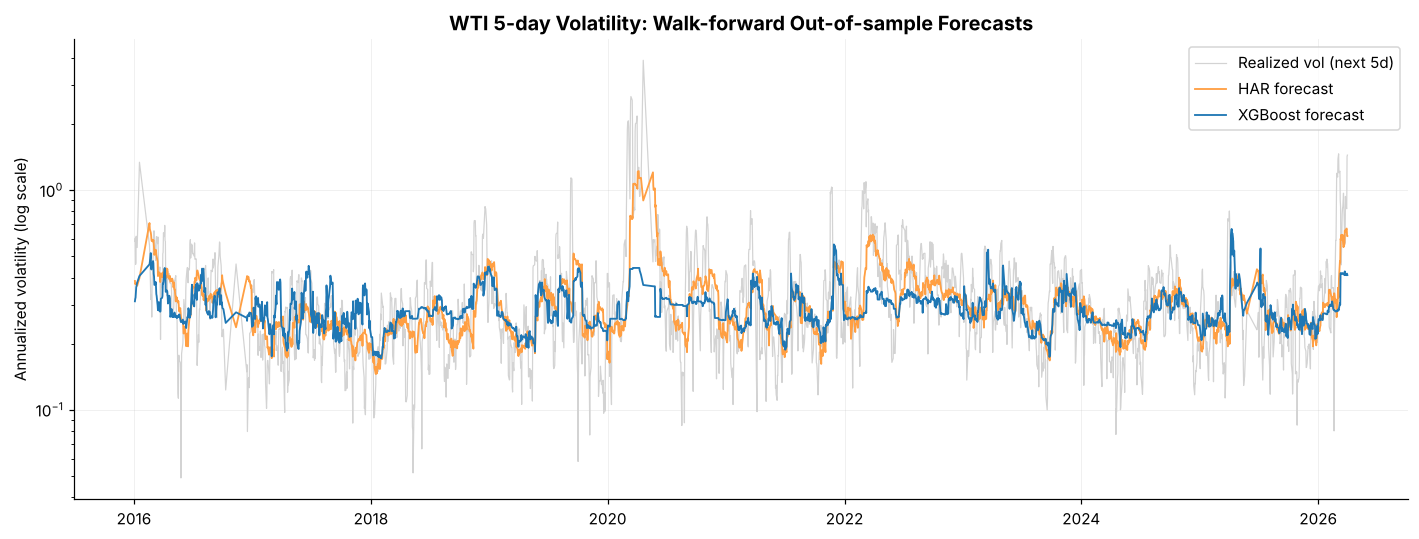

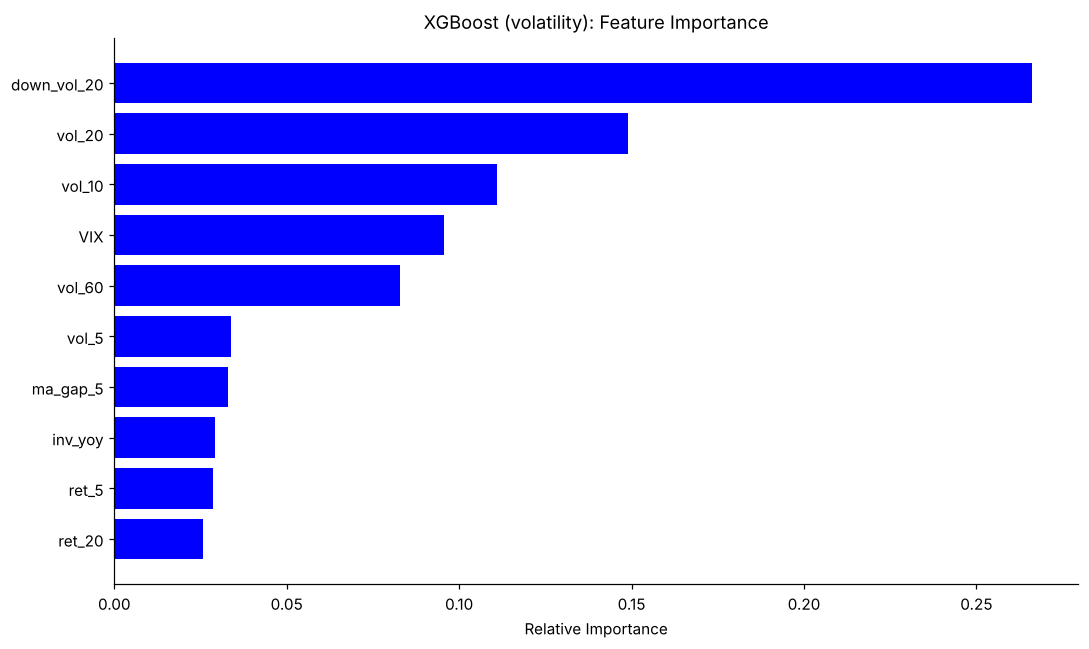

Lasso kept 8 of 21 features


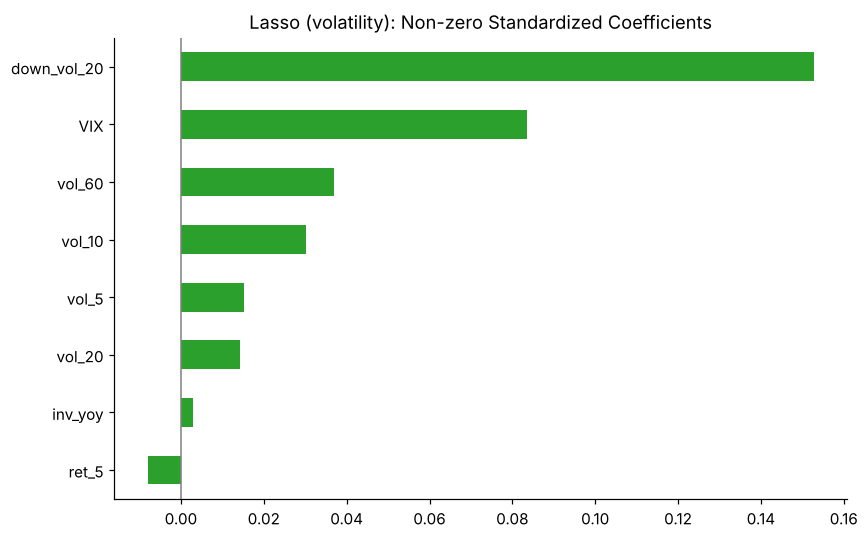

In [26]:
plt.figure(figsize=(13, 5))
plt.plot(ev.index, ev['rv_fwd'], color='lightgrey', linewidth=0.8, label='Realized vol (next 5d)')
plt.plot(ev.index, np.exp(ev['pred_har']), color='#ff9f43', linewidth=1.2, label='HAR forecast')
plt.plot(ev.index, np.exp(ev['pred_xgb']), color='#1f77b4', linewidth=1.2, label='XGBoost forecast')
plt.yscale('log')
plt.ylabel('Annualized volatility (log scale)')
plt.title(f'WTI {vol_h}-day Volatility: Walk-forward Out-of-sample Forecasts', fontsize=13, fontweight='bold')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('figures/vol_forecasts_oos.png', dpi=150, bbox_inches='tight')
plt.show()

# feature importance of the XGBoost model
plot_feature_importance(vol_model, vol_feature_cols, title='XGBoost (volatility): Feature Importance')
# lasso feature importance
lasso_coef = pd.Series(lasso[-1].coef_, index=vol_feature_cols)
print(f"Lasso kept {(lasso_coef != 0).sum()} of {len(lasso_coef)} features")
plt.figure(figsize=(8, 5))
lasso_coef[lasso_coef != 0].sort_values().plot.barh(color='#2ca02c')
plt.title('Lasso (volatility): Non-zero Standardized Coefficients')
plt.axvline(0, color='grey', linewidth=1)
plt.tight_layout()
plt.savefig('figures/lasso_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Volatility-targeting overlay
Long-only position sized as `target_vol / forecast_vol` (30% target, 1.5x cap), net of VIX-scaled costs.

In [27]:
# volatility targeting: weight = target_vol / forecast volatility, capped at max_lev, long only
def weight_backtest(d, weight, name, slippage_mult=1.0, start=None, end=None):
    out = d.loc[start:end].copy()
    out = out[out.index <= d['fwd_ret_1'].last_valid_index()]
    out['w'] = weight.reindex(out.index).ffill().fillna(0)
    out['turnover'] = out['w'].diff().abs()
    out.loc[out.index[0], 'turnover'] = abs(out['w'].iloc[0])
    out['cost'] = out['turnover'] * cost_bps * slippage_mult * 1e-4 * (1 + out['VIX'].ffill().fillna(20) / 50)
    out['net_ret'] = (out['w'] * out['fwd_ret_1']).fillna(0) - out['cost']
    out['equity'] = (1 + out['net_ret']).cumprod()
    metrics = {
        'Strategy': name,
        'Ann. Return': out['equity'].iloc[-1] ** (ann / len(out)) - 1,
        'Ann. Vol': out['net_ret'].std() * np.sqrt(ann),
        'Sharpe': out['net_ret'].mean() / (out['net_ret'].std() + 1e-12) * np.sqrt(ann),
        'Max Drawdown': (out['equity'] / out['equity'].cummax() - 1).min(),
        'Vol of 3m vol': (out['net_ret'].rolling(63).std() * np.sqrt(ann)).std(),
        'Avg Leverage': out['w'].mean(),
    }
    return out, metrics

strategy_weights = {
    'Buy & Hold (1x)':     pd.Series(1.0, index=vol_oos.index),
    'VolTarget - Naive':   (target_vol / np.exp(vol_oos['pred_naive'])).clip(upper=max_lev),
    'VolTarget - HAR':     (target_vol / np.exp(vol_oos['pred_har'])).clip(upper=max_lev),
    'VolTarget - XGBoost': (target_vol / np.exp(vol_oos['pred_xgb'])).clip(upper=max_lev),
}
vt_res, vt_rows = {}, []
for name, w in strategy_weights.items():
    vt_res[name], m = weight_backtest(vol_oos, w, name)
    vt_rows.append(m)
vt_table = pd.DataFrame(vt_rows).set_index('Strategy')
fmt = {'Ann. Return': '{:.2%}', 'Ann. Vol': '{:.2%}', 'Sharpe': '{:.3f}',
       'Max Drawdown': '{:.2%}', 'Vol of 3m vol': '{:.2%}', 'Avg Leverage': '{:.2f}'}
vt_table.style.format(fmt)

,Ann. Return,Ann. Vol,Sharpe,Max Drawdown,Vol of 3m vol,Avg Leverage
Strategy,,,,,,
Buy & Hold (1x),2.38%,40.85%,0.264,-76.58%,16.58%,1.00
VolTarget - Naive,3.51%,33.37%,0.272,-65.34%,5.75%,0.98
VolTarget - HAR,3.79%,36.93%,0.288,-68.82%,6.97%,1.07
VolTarget - XGBoost,0.42%,39.42%,0.210,-72.71%,11.50%,1.07


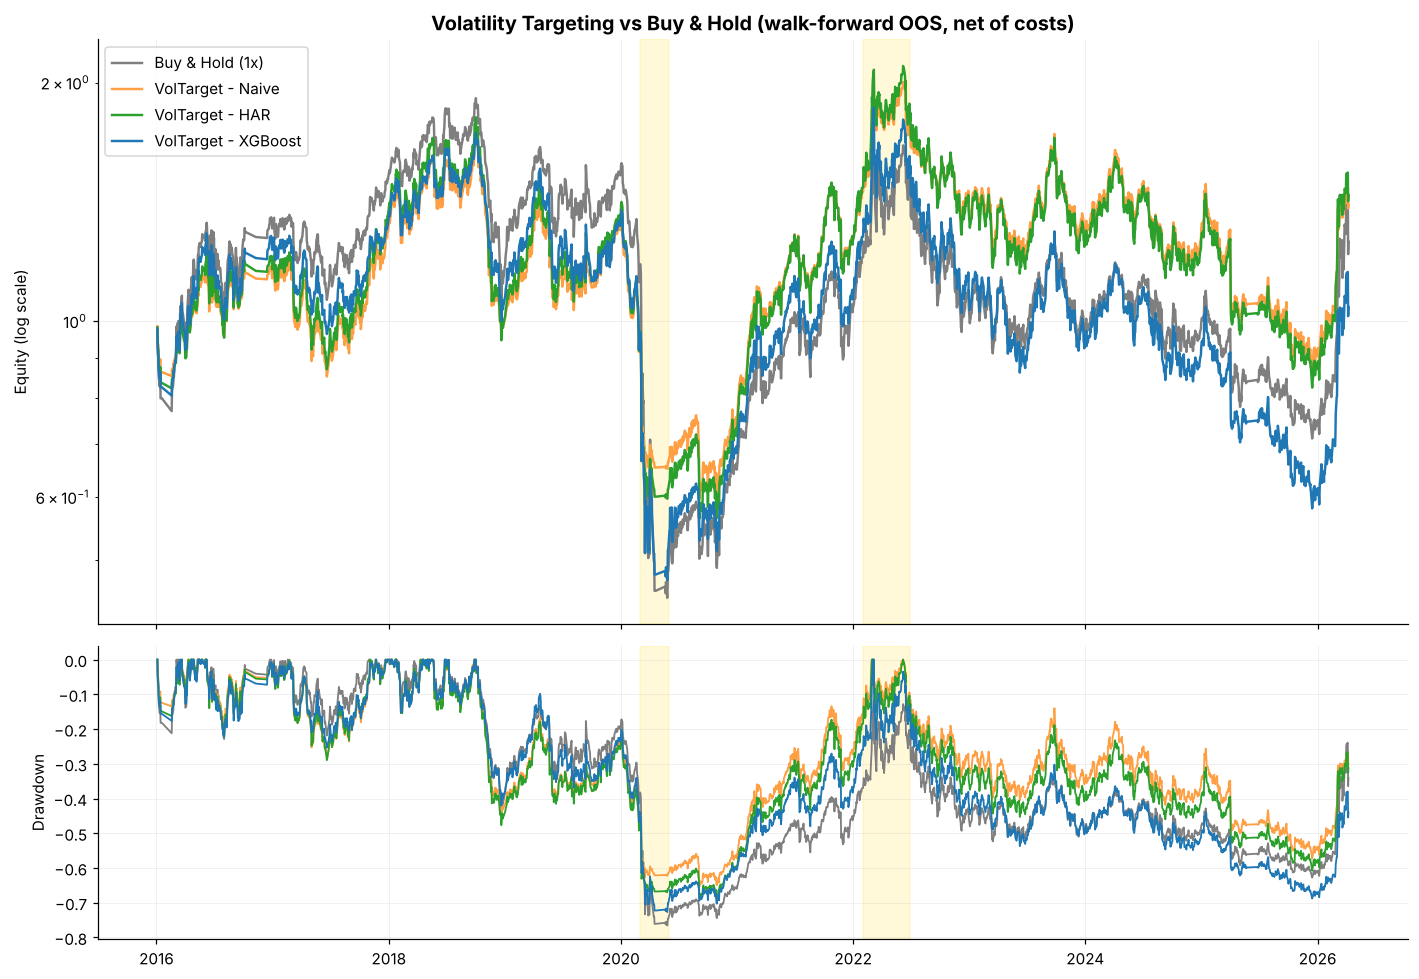

In [28]:
colors_vt = {'Buy & Hold (1x)': '#7f7f7f', 'VolTarget - Naive': '#ff9f43',
             'VolTarget - HAR': '#2ca02c', 'VolTarget - XGBoost': '#1f77b4'}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for name, res in vt_res.items():
    ax1.plot(res.index, res['equity'], label=name, color=colors_vt[name], linewidth=1.6)
    ax2.plot(res.index, res['equity'] / res['equity'].cummax() - 1, color=colors_vt[name], linewidth=1.2)
for sc in scenarios:
    for ax in (ax1, ax2):
        ax.axvspan(pd.Timestamp(sc['start']), pd.Timestamp(sc['end']), color='gold', alpha=0.15)
ax1.set_yscale('log')
ax1.set_title('Volatility Targeting vs Buy & Hold (walk-forward OOS, net of costs)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Equity (log scale)')
ax1.legend(loc='upper left')
ax1.grid(alpha=0.2)
ax2.set_ylabel('Drawdown')
ax2.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('figures/vol_targeting_equity.png', dpi=150, bbox_inches='tight')
plt.show()

### Crisis stress tests
Transaction costs multiplied by 5x (2020) and 3x (2022) to simulate liquidity stress.

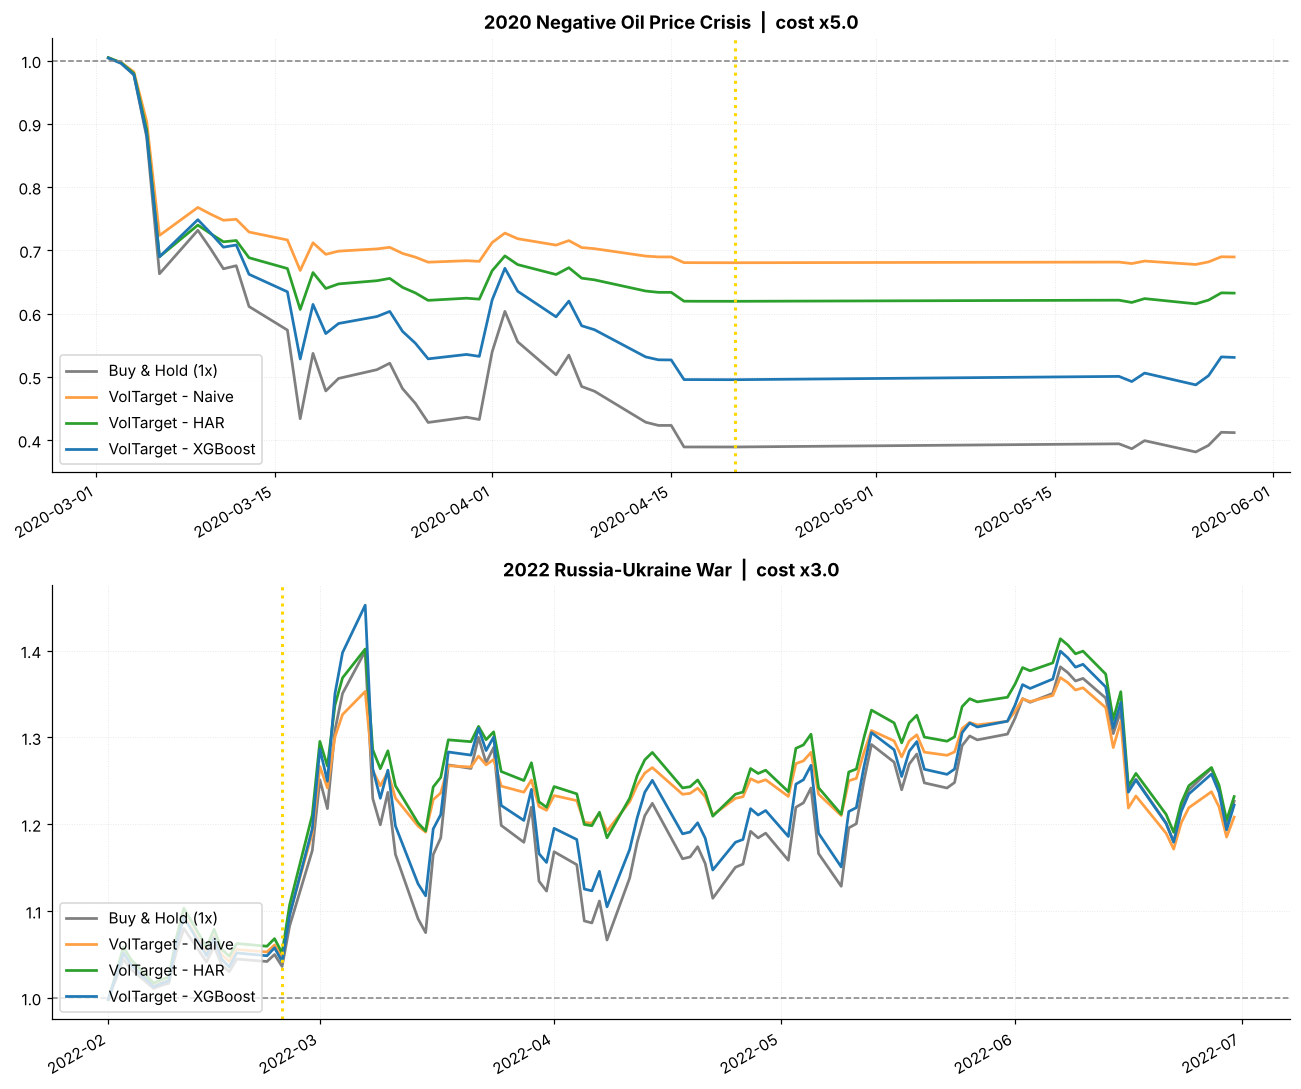

In [29]:
crisis_rows = []
fig, axes = plt.subplots(len(scenarios), 1, figsize=(12, 5 * len(scenarios)))
for ax, sc in zip(np.atleast_1d(axes), scenarios):
    for name, w in strategy_weights.items():
        res, m = weight_backtest(vol_oos, w, name, slippage_mult=sc['mult'], start=sc['start'], end=sc['end'])
        crisis_rows.append({'Scenario': sc['name'], 'Strategy': name,
                            'Cum_Ret': res['equity'].iloc[-1] - 1, 'Max_Drawdown': m['Max Drawdown'], 'Avg Leverage': m['Avg Leverage']})
        ax.plot(res.index, res['equity'], label=name, color=colors_vt[name], linewidth=1.8)
    ax.axvline(pd.Timestamp(sc['event_date']), color='gold', linestyle=':', linewidth=2)
    ax.axhline(1, color='grey', linestyle='--', linewidth=1)
    ax.set_title(f"{sc['name']}  |  cost x{sc['mult']}", fontsize=12, fontweight='bold')
    ax.legend(loc='lower left')
    ax.grid(alpha=0.3, linestyle=':')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.savefig('figures/crisis_stress_test.png', dpi=150, bbox_inches='tight')
plt.show()
crisis_table = pd.DataFrame(crisis_rows).set_index(['Scenario', 'Strategy'])
crisis_table.style.format({'Cum_Ret': '{:.2%}', 'Max_Drawdown': '{:.2%}', 'Avg Leverage': '{:.2f}'})

## 7. Summary

In [30]:
# Summary
x, bh, vx = vol_eval.loc['XGBoost'], vt_table.loc['Buy & Hold (1x)'], vt_table.loc['VolTarget - XGBoost']
# return
print("\n[Return Predictability] 2024- ")
print(f"  Directional alpha is weak. 5d Rank IC: {logic_metrics['Rank IC (5d)']}")
print(f"  L/S Cumulative: {logic_metrics['Cumulative Return']} | Benchmark (B&H WTI): {logic_metrics['Buy&Hold WTI']}")

# volatility
print("\n[Volatility Predictability]")
print(f"  XGBoost: Rank IC = {x['Rank IC']:.3f}, R2 = {x['R2 (OOS)']:.3f}")
print("\n  Model Ranking (OOS RMSE):")
print(f"  {'Rank':<5} {'Model':<22} {'RMSE':<10} {'Rank IC':<10} {'Win Rate vs HAR'}")
print("  " + "-" * 60)
for rank, (name, row) in enumerate(vol_eval.sort_values('RMSE (log vol)').iterrows(), 1):
    har_stat = f"{beats_har[name]}/{len(yearly)} yrs" if name in beats_har else "-"
    print(f"  {rank:<5} {name:<22} {row['RMSE (log vol)']:<10.4f} {row['Rank IC']:<10.3f} {har_stat}")

n_keep = (lasso_coef != 0).sum()
print(f"\n  [Regularization] Lasso retained {n_keep}/{len(lasso_coef)} features in the final fit.")

# Compare all overlays
print("\n[Strategy Comparison] Net of Costs, 2016-2026")
print(f"  {'Strategy':<22} {'Sharpe':>7} {'Max DD':>9} {'Ann. Vol':>9} {'Vol of 3m vol':>14}")
print("  " + "-" * 64)
for name, row in vt_table.iterrows():
    print(f"  {name:<22} {row['Sharpe']:>7.3f} {row['Max Drawdown']:>9.1%} {row['Ann. Vol']:>9.1%} {row['Vol of 3m vol']:>14.1%}")
# crisis
print("\n[Crisis Stress Test] Max Drawdown")
print(f"  {'Scenario':<32} " + " ".join(f"{n.replace('VolTarget - ', 'VT-'):>14}" for n in strategy_weights))
for sc in scenarios:
    vals = [crisis_table.loc[(sc['name'], n)]['Max_Drawdown'] for n in strategy_weights]
    print(f"  {sc['name']:<32} " + " ".join(f"{v:>14.1%}" for v in vals))



[Return Predictability] 2024- 
  Directional alpha is weak. 5d Rank IC: -0.0688
  L/S Cumulative: -44.24% | Benchmark (B&H WTI): 40.52%

[Volatility Predictability]
  XGBoost: Rank IC = 0.398, R2 = 0.145

  Model Ranking (OOS RMSE):
  Rank  Model                  RMSE       Rank IC    Win Rate vs HAR
  ------------------------------------------------------------
  1     Random Forest          0.4358     0.449      6/11 yrs
  2     HAR                    0.4407     0.442      -
  3     Ridge                  0.4498     0.455      7/11 yrs
  4     Lasso                  0.4587     0.446      6/11 yrs
  5     XGBoost                0.4657     0.398      4/11 yrs
  6     Naive (hist vol 20d)   0.4736     0.438      1/11 yrs

  [Regularization] Lasso retained 8/21 features in the final fit.

[Strategy Comparison] Net of Costs, 2016-2026
  Strategy                Sharpe    Max DD  Ann. Vol  Vol of 3m vol
  ----------------------------------------------------------------
  Buy & Hold (1x)   